# Imports e Bibliotecas

In [ ]:
import pandas as pd
import numpy as np
from enum import Enum
from math import floor as floor
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Dataset

In [ ]:
!gdown "https://drive.google.com/uc?id=1wmV6xCAy6d86HmSjBli2CxJZoVgzHL43"
!gdown "https://drive.google.com/uc?id=1PbCBbx1Vzi_6pWpib_FEmTZOrhzwAVoo"
!gdown "https://drive.google.com/uc?id=1w96QRLlQb-9EF24gABQykY43y-Mm5BJD"
!gdown "https://drive.google.com/uc?id=101teITG73DZLLFV3rBb7oDi6dD9gYNDI"
!gdown "https://drive.google.com/uc?id=11ZXPtQf_xtkXvP6aWIKl4TvzAkmNrgSr"
!gdown "https://drive.google.com/uc?id=1TejfsryTdtQz12y7X9F3pH8ThGdxqPS2"
!gdown "https://drive.google.com/uc?id=1cikzjWFx000dAo5q15IhafYoDexMQhoF"

Downloading...
From: https://drive.google.com/uc?id=1wmV6xCAy6d86HmSjBli2CxJZoVgzHL43
To: /content/Corpus_DeepSeek-V3.csv
100% 2.54M/2.54M [00:00<00:00, 179MB/s]
Downloading...
From: https://drive.google.com/uc?id=1PbCBbx1Vzi_6pWpib_FEmTZOrhzwAVoo
To: /content/Corpus_gpt-2.csv
100% 667k/667k [00:00<00:00, 116MB/s]
Downloading...
From: https://drive.google.com/uc?id=1w96QRLlQb-9EF24gABQykY43y-Mm5BJD
To: /content/Corpus_grok-1.csv
100% 94.6k/94.6k [00:00<00:00, 72.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=101teITG73DZLLFV3rBb7oDi6dD9gYNDI
To: /content/Corpus_llama.csv
100% 4.64M/4.64M [00:00<00:00, 38.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=11ZXPtQf_xtkXvP6aWIKl4TvzAkmNrgSr
To: /content/Corpus_llama3.csv
100% 978k/978k [00:00<00:00, 80.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1TejfsryTdtQz12y7X9F3pH8ThGdxqPS2
To: /content/ValidacaoExtra.csv
100% 8.47k/8.47k [00:00<00:00, 23.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1c

In [ ]:
deep_seek_v3_coleta = pd.read_csv("/content/Corpus_DeepSeek-V3.csv")
gpt_2_coleta = pd.read_csv("/content/Corpus_gpt-2.csv")
grok_1_coleta = pd.read_csv("/content/Corpus_grok-1.csv")
llama_coleta = pd.read_csv("/content/Corpus_llama.csv")
llama3_coleta = pd.read_csv("/content/Corpus_llama3.csv")

In [ ]:
deep_seek_v3_coleta['Repositorio'] = 'DeepSeek_V3'
gpt_2_coleta['Repositorio'] = 'GPT_2'
grok_1_coleta['Repositorio'] = 'Grok_1'
llama_coleta['Repositorio'] = 'Llama'
llama3_coleta['Repositorio'] = 'Llama3'

In [ ]:
todos = pd.concat([deep_seek_v3_coleta, gpt_2_coleta, grok_1_coleta, llama_coleta, llama3_coleta], ignore_index=True)

## Adicionando coluna $Validadas$
Representa se a *issue* está nos conjuntos das *issues* validadas como relacionadas à ética ou não

In [ ]:
id_issues_validadas = pd.read_csv("/content/validadas.csv")

In [ ]:
def addColunaValidada(dataset, id_issues_validadas):
  dataset['Validada'] = dataset['IdIssue'].isin(id_issues_validadas['IdIssue'])
  return dataset

In [ ]:
todos = addColunaValidada(todos,id_issues_validadas)

## Identificando quem contribuiu para discussão

In [ ]:
contribuintes = pd.read_csv('/content/ValidacaoExtra.csv')

In [ ]:
contribuintes['Soma_Total'] = contribuintes['QtdComentarios'] + contribuintes['Info']
soma_agrupada = contribuintes.groupby(['IdIssue', 'Autor'])['Soma_Total'].sum().reset_index()
todos = todos.merge(
    soma_agrupada,
    left_on=['IdIssue', 'AutorComentario'],
    right_on=['IdIssue', 'Autor'],
    how='left'
)
todos.rename(columns={'Soma_Total': 'Volume'}, inplace=True)
todos['Volume'] = todos['Volume'].fillna(0)
todos.drop(columns=['Autor'], inplace=True)

## Anonimização

In [ ]:
def anonimizaAutores(dataset):
  cp = dataset.copy()
  cp['AutorComentario'] = pd.factorize(cp['AutorComentario'])[0]
  cp['IdIssue'] = pd.factorize(cp['IdIssue'])[0]
  cp = cp.drop(columns=['LinkIssue','NumeroComentario','Comentario','Info'])
  return cp

### Split Dataset
1. Dataset somente com *issues* validadas como relacionadas à ética
3. Dataset somente com *issues* invalidadas como relacionadas à ética
---
> Permite avaliar se existe transversalidade fora do contexto de investigação de aspectos éticos

> Quero avaliar também a visão geral, ou seja, se um usuário que participou de uma discussão que cobria aspectos éticos também abordou outros temas não relacionados a aspectos éticos ao longo dos repositórios

In [ ]:
todos_anon=anonimizaAutores(todos)
todos_validadas=todos_anon[todos_anon['Validada']]
todos_invalidadas=todos_anon[todos_anon['Validada']==False]

Conferindo como os dados ficaram no dataframe (pequeno trecho)

In [ ]:
todos_anon.head(10) #as colunas: Termos_Info, Termos_Comentario e Termos poderiam ser descartadas também, uma vez que não foram usadas

,IdIssue,AutorComentario,Termos_Info,Termos_Comentario,Termos,Repositorio,Validada,Volume
0,0,0,,,,DeepSeek_V3,False,0.0
1,1,1,,,,DeepSeek_V3,False,0.0
2,2,2,,,,DeepSeek_V3,True,1.0
3,2,3,,,,DeepSeek_V3,True,0.0
4,2,2,,"ethics, safety","ethics, safety",DeepSeek_V3,True,1.0
5,2,4,,,,DeepSeek_V3,True,0.0
6,2,5,,,,DeepSeek_V3,True,0.0
7,2,2,,,,DeepSeek_V3,True,1.0
8,2,6,,,,DeepSeek_V3,True,0.0
9,2,6,,,,DeepSeek_V3,True,0.0


# Estrutura de Dados

Uma dificuldade deste trabalho foi definir a modelagem das entidades. A estrutura de grafo parecia clara, mas como representar repositório, issue e usuário em 2 entidades (nó/aresta) foi um pouco complexo. Primeiramente, a relação entre elementos, todo repositório possui nenhuma ou várias issues (neste cenário, tem pelo menos várias issues), toda issue pertence a um repositório e pode ter um ou mais participantes, um usuário pode participar de 1 ou várias issues em um ou vários repositórios. Dependendo da modelagem poderia criar uma dependência circular, por exemplo, se uma issue tem vários participantes e um participante tem uma lista de issues.

O que pensei, como o objetivo é analisar a participação de um usuários em diferentes repositórios, preferi dar um foco maior nele, sendo assim ele iria deter as informações para modelagem e análise deste projeto, em suma, o usuário terá uma lista de issues nas quais este participa e cada issue terá a informação do repositório ao qual ela pertence (afinal uma issue pertence a um e somente um repositório)

## Separação de IDs

Separo os ids das validadas/invalidadas como relacionadas à ética para uso futuro

In [ ]:
ids_validados = set(todos_validadas['IdIssue'].tolist())

In [ ]:
ids_invalidados = set(todos_invalidadas['IdIssue'].tolist())

## Enum Repositórios

Padroniza e facilita a referenciação a um repositório nas EDs

In [ ]:
class Repositorios(Enum):
  DeepSeek_V3 = 1
  Grok_1 = 2
  GPT_2 = 3
  Llama = 4
  Llama3 = 5

## Issue

Entidade auxiliar que irá compor um atributo da entidade *Nó Usuário*

> Carrega o id da issue, o repositório ao qual pertence e se nela existe uma discussão que aborda aspecto ético

In [ ]:
class Issue:
  def __init__(self, id_issue:int, repositorio:Repositorios):
    self.id_issue = id_issue
    self.repositorio = repositorio
    self.relacionada_etica = self.verificaValidada()

  def verificaValidada(self):
    if self.id_issue in ids_validados:
      return True
    else:
      return False

## Heap

Durante a construção das arestas, percebi o quão caro seria ligar os nós usando somente listas. Um nó se liga a outro se 2 usuários estão participando de uma mesma issue, ou seja, a issue é a aresta.

Se eu colocasse uma lista de usuários em Issue só faria uma dependência circular que queria evitar

Voltando, para popular a matriz de adjacência, seria preciso olhar o id da issue de um usuário e buscar na lista de issues de todos os outros usuários esse mesmo id para todas as issues. Mesmo que eu marcasse as issues já pesquisadas, isso ainda seria caro. Considerando todas as issues com um tamanho $x$ e $n$ a quantidade de usuários (nós), buscar por um id de issue linearmente seria demandaria uma quantidade absurda de operações.

Por isso, pensei em usar uma ED auxiliar para reduzir o custo dessa busca, tabela hash poderia ser complicado desenvolver uma função hash decente num tempo ábil. Pensei em árvore auto-balanceável pelo custo da busca no pior caso ser $O(log(n))$ e não seria preciso ordenar a entrada. Mas, um heap além de ser mais simples de implementar neste cenário, não perde em complexidade para a árvore, além de ser usado em algoritmos que atuam sobre grafos como Dijkstra

In [ ]:
class Max_Heap:
  def __init__(self):
    self.issues = [None] #variável dummy para usar lista 1-indexada
    self.tam = 0

  #algoritmos adaptados daqueles apresentados nas aulas expositivas
  def pai(self, indice):
    return floor(indice/2)

  def esquerda(self, indice):
    return 2*indice

  def direita(self, indice):
    return 2*indice + 1

  def troca(self, indiceA, indiceB):
    aux = self.issues[indiceA]
    self.issues[indiceA] = self.issues[indiceB]
    self.issues[indiceB] = aux

  def max_heapify(self, indice):
    esq = self.esquerda(indice)
    dir = self.direita(indice)
    maior = indice

    if esq <= self.tam and self.issues[esq].id_issue > self.issues[maior].id_issue:
      maior = esq
    if dir <= self.tam and self.issues[dir].id_issue > self.issues[maior].id_issue:
      maior = dir

    if maior != indice:
      self.troca(indice, maior)
      self.max_heapify(maior)

  def constroi_max_heap(self, issues):
    tamanho_lista = len(issues)
    self.issues = [None]+list(issues)
    self.tam = tamanho_lista
    for i in range(floor(tamanho_lista/2),0,-1):
      self.max_heapify(i)

  def heap_max(self):
    return self.issues[1]

  def extraiMax(self):
    if self.tam < 1:
      return None

    max = self.issues[1]
    self.issues[1] = self.issues[self.tam]
    self.tam-=1
    self.issues.pop()
    if self.tam > 0:
      self.max_heapify(1)
    return max

  def insert(self, chave):
    self.tam += 1
    self.issues.append(chave)

    indice = self.tam
    p = self.pai(indice)

    while indice > 1 and self.issues[p].id_issue < self.issues[indice].id_issue:
        self.troca(indice, p)
        indice = p
        p = self.pai(indice)

## Nó Usuário

Entidade principal, um nó carrega seu id, uma lista de issues das quais este participou, repositório em mais participou (pensei nisso para uma outra análise dependendo dos resultados, poderia ser substituído por um conjunto incluindo todos repositórios da sua lista de issues), o quanto ele contribuiu para uma discussão que envolvia aspectos éticos

In [ ]:
class No_Usuario:
  def __init__(self, id_participante:int, issues:list):
    self.id_participante = id_participante
    self.issues = issues
    self.repositorio_predominante = self.predominancia_repos() #indica o repo que um usuário mais participou ->
                                                                #pode ser bom ter uma lista de todos os repos q participou
    self.volume_discussao_aspectos_eticos = self.discussao_aspectos_eticos()

  # cria discionário com nome do repositório e quantas vezes o repositório apareceu na lista
  # de issues do usuario
  # então, retorna o nome do repositório com maior quantidade de ocorrências na lista de issues do usuário
  def predominancia_repos(self):
    contabiliza_repo = {Repositorios(1).name:0,
                        Repositorios(2).name:0,
                        Repositorios(3).name:0,
                        Repositorios(4).name:0,
                        Repositorios(5).name:0}

    for i in self.issues:
      if i.repositorio.name in contabiliza_repo.keys():
        contabiliza_repo[i.repositorio.name]+=1

    maior = 0
    for i in contabiliza_repo.values():
      if maior < i:
        maior = i

    for chave, valor in contabiliza_repo.items():
      if valor == maior:
        chave_maior = chave

    return chave_maior

  def discussao_aspectos_eticos(self):
    #1.verificar se usuario esta em issue validada -> self.issues.id_issue in ids_validadas
    #2.nas issues validadas do usuario, buscar em todas_validadas o id_participante dele em AutorComentario
    #3.agrupar usuarios filtrados por AutorComentario e somar dado na coluna Volume em todas_validadas pelos agrupamentos
    #4.retornar resultado
    #parece IA, mas fui eu qm escreveu!!!

    ids_issues_usuario = [i.id_issue for i in self.issues]

    df_filtrado = todos_validadas[todos_validadas['IdIssue'].isin(ids_issues_usuario)]

    filtro_autor = df_filtrado['AutorComentario'] == self.id_participante
    df_filtrado = df_filtrado[filtro_autor]

    volume_total = int(df_filtrado['Volume'].sum())

    return volume_total


### Colocando dados num formato usável

Dataframe -> Issue e No_Usuario

In [ ]:
issues = []
participantes = []

for row in todos_anon.itertuples(index=False):
  try:
      r = Repositorios[row.Repositorio]
  except KeyError:
      r = None
  issue = Issue(row.IdIssue,r)
  issues.append(issue)
  participante = No_Usuario(row.AutorComentario, [issue]) #juntar info de diferentes linhas de autorComentario em um unico nodo
  participantes.append(participante)

Como um mesmo usuário pode estar espalhado em várias issues, ele pode representar mais de um nó, o que não é interessante. Por isso, o método abaixo que encontra esses usuários espalhados e mescla suas informaçõe

In [ ]:
def localizaMescla_participante_repetido(participantes):
    participantes_unicos = {}

    for participante in participantes:
        id_part = participante.id_participante

        if id_part not in participantes_unicos: #agrupa issues repetidas
            issues_limpas = []
            ids_vistos = set()

            for issue in participante.issues:
                if issue.id_issue not in ids_vistos:
                    issues_limpas.append(issue)
                    ids_vistos.add(issue.id_issue)

            participante.issues = issues_limpas
            participantes_unicos[id_part] = participante

        else: #se usuario ja foi visto anteriormente, mescla as informações das ocorrências
            p_existente = participantes_unicos[id_part]
            p_existente.volume_discussao_aspectos_eticos += participante.volume_discussao_aspectos_eticos

            ids_issues_existentes = {issue.id_issue for issue in p_existente.issues}

            for nova_issue in participante.issues:
                if nova_issue.id_issue not in ids_issues_existentes:
                    p_existente.issues.append(nova_issue)
                    ids_issues_existentes.add(nova_issue.id_issue)

    return list(participantes_unicos.values())

In [ ]:
#execução do método da célula acima + depuração
participantes_tratados = localizaMescla_participante_repetido(participantes)
for i in participantes_tratados:
  print('=====================================================================')
  print(f'Id_Participante={i.id_participante}')
  print(f'Volume={i.volume_discussao_aspectos_eticos}')
  print(f'Issues:')
  print('*********************************************************************')
  for j in i.issues:
    print(f'\tId Issue = {j.id_issue}')
    print(f'\tRepositório = {j.repositorio.name}')
    print(f'\tValidada = {j.relacionada_etica}')

  print('*********************************************************************')
  print('=====================================================================')

A saída de streaming foi truncada nas últimas 5000 linhas.
	Id Issue = 1780
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3493
Volume=0
Issues:
*********************************************************************
	Id Issue = 1781
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3494
Volume=0
Issues:
*********************************************************************
	Id Issue = 1782
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3495
Volume=0
Issues:
*********************************************************************
	Id Issue = 1783
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3496
Volume=0
Issues:
*********************************************************************
	Id I

Abaixo é repetido o mesmo processo, mas as partições do dataset

#### Validadas como relacionada à ética

In [ ]:
issues_validadas = []
participantes_validados = []

for row in todos_validadas.itertuples(index=False):
  try:
      r = Repositorios[row.Repositorio]
  except KeyError:
      r = None
  issueValidada = Issue(row.IdIssue,r)
  issues_validadas.append(issue)
  participante = No_Usuario(row.AutorComentario, [issueValidada]) #juntar info de diferentes linhas de autorComentario em um unico nodo
  participantes_validados.append(participante)

In [ ]:
participantesValidados_tratados = localizaMescla_participante_repetido(participantes_validados)
for i in participantesValidados_tratados:
  print('=====================================================================')
  print(f'Id_Participante={i.id_participante}')
  print(f'Volume={i.volume_discussao_aspectos_eticos}')
  print(f'Issues:')
  print('*********************************************************************')
  for j in i.issues:
    print(f'\tId Issue = {j.id_issue}')
    print(f'\tRepositório = {j.repositorio.name}')
    print(f'\tValidada = {j.relacionada_etica}')

  print('*********************************************************************')
  print('=====================================================================')

Id_Participante=2
Volume=16
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=3
Volume=0
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=4
Volume=0
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=5
Volume=0
Issues:
*********************************************************************
	Id Issue = 2
	Repositório = DeepSeek_V3
	Validada = True
*********************************************************************
Id_Participante=6
Volume=0
Issues:
********************************

#### Invalidadas como relacionada à ética

In [ ]:
issuesInvalidadas = []
participantes_invalidados = []

for row in todos_invalidadas.itertuples(index=False):
  try:
      r = Repositorios[row.Repositorio]
  except KeyError:
      r = None
  issue_invalidada = Issue(row.IdIssue,r)
  issuesInvalidadas.append(issue)
  participante = No_Usuario(row.AutorComentario, [issue_invalidada]) #juntar info de diferentes linhas de autorComentario em um unico nodo
  participantes_invalidados.append(participante)

In [ ]:
participantesInvalidados_tratados = localizaMescla_participante_repetido(participantes_invalidados)
for i in participantesInvalidados_tratados:
  print('=====================================================================')
  print(f'Id_Participante={i.id_participante}')
  print(f'Volume={i.volume_discussao_aspectos_eticos}')
  print(f'Issues:')
  print('*********************************************************************')
  for j in i.issues:
    print(f'\tId Issue = {j.id_issue}')
    print(f'\tRepositório = {j.repositorio.name}')
    print(f'\tValidada = {j.relacionada_etica}')

  print('*********************************************************************')
  print('=====================================================================')

A saída de streaming foi truncada nas últimas 5000 linhas.
Volume=0
Issues:
*********************************************************************
	Id Issue = 1773
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3487
Volume=0
Issues:
*********************************************************************
	Id Issue = 1774
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3488
Volume=0
Issues:
*********************************************************************
	Id Issue = 1775
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3489
Volume=0
Issues:
*********************************************************************
	Id Issue = 1776
	Repositório = Llama
	Validada = False
*********************************************************************
Id_Participante=3490
Volum

## Grafo

ED principal, nela cada usuário representa um nó e a participação de dois usuários numa mesma issue representa a aresta.

Para investigar a transversalidade, adotei 2 algoritmos para métrica de centralidade de intermediação (betweenness centrality), sendo DFS e algoritmo de Brandes. Outras funções auxiliares foram desenvolvidas para facilitar a implementação dos métodos principais (criação de aresta, DFS e brandes)

A matriz de adjacência ao invés de matriz de incidência ou lista de adjacência por representar melhor a modelagem. Primeiramente, por quantidade de vértices, qualquer uma seria "aceitável", contudo quando olhamos para arestas, elas são inúmeras, o que levaria a um gasto de memória desnecessário. Apesar da matriz de incidência ser uma possível facilitadora para representar os dados das arestas (issues), não vi como realmente necessária

**Observação**:

---

> O algoritmo de Brandes originalmente é usado em grafos **não ponderados** e **direcionados**, o grafo que modelei é **não ponderado** e **não-direcionado** sendo necessária adaptação como sugerido em [Wikipedia - Algoritmo de Brandes](https://en-wikipedia-org.translate.goog/wiki/Brandes%27_algorithm?_x_tr_sl=en&_x_tr_tl=pt&_x_tr_hl=pt&_x_tr_pto=tc)

In [ ]:
#matriz de adjacência, nós se conectam pela quantidade de issues em ambos. Se 2 usuarios participaram de 3 issues ao mesmo tempo, eles tem 3 conexoes
class Grafo:
  def __init__(self, lista_nos):
    self.lista_nos = lista_nos
    self.matrizAdjacencia = []
    self.inicializaMatrizAdjacencia()
    self.criar_aresta()

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ INICIALIZA MATRIZ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def inicializaMatrizAdjacencia(self):
    n = len(self.lista_nos)
    #cria matriz nxn vazia
    self.matrizAdjacencia = [[[] for _ in range(n)] for _ in range(n)]
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ EXTRAI NO DADO UM ID ~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def extraiNo_dadoId(self, id):
    for i in self.lista_nos:
      #encontra vértice dado seu id
      if i.id_participante == id:
        return i
    return None
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ CRIA ARESTA ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def criar_aresta(self):
    dicionario_issues = {}
    #entrada para heap global
    for i in self.lista_nos:
      for j in i.issues:
        dicionario_issues[j.id_issue] = j

    #heap global - olha o primeiro elemento e compara com o primeiro elemento
    #do heap de cada usuario (lista de issues)
    h = Max_Heap()
    h.constroi_max_heap(list(dicionario_issues.values()))

    heaps_usuarios = [] #id usuario + respectivo heap

    for no in self.lista_nos:
      h_usuario = Max_Heap()
      h_usuario.constroi_max_heap(no.issues)
      elemento_usuario = {"id_participante": no.id_participante, "heap": h_usuario}
      heaps_usuarios.append(elemento_usuario)

    #enquanto o heap globar tiver elementos
    while h.tam > 0:
      m_val = h.extraiMax()
      #extrai o máx do heap global e busca por correspondência no heap dos usuários
      m_id = m_val.id_issue
      nome_repo = m_val.repositorio.name

      usuariosM = [] #lista de usuários conectados para aquela issue

      for i in range(len(heaps_usuarios)):
          #busca no heap de cada usuário a correspondência
          while heaps_usuarios[i]['heap'].tam > 0:
              s = heaps_usuarios[i]['heap'].heap_max()

              if s.id_issue == m_id:
                  heaps_usuarios[i]['heap'].extraiMax()
                  usuariosM.append(i) #encontrada correspondência - adiciona na lista de usuários que fazem conexão
              else:
                break
      #faz a aresta
      for i in range(len(usuariosM)):
          for j in range(i + 1, len(usuariosM)):
              u1 = usuariosM[i]
              u2 = usuariosM[j]

              aresta = (m_id, nome_repo)

              self.matrizAdjacencia[u1][u2].append(aresta)
              self.matrizAdjacencia[u2][u1].append(aresta)
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ VIZINHOS DE UM NÓ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def vizinhos(self, id_participante):
    v = set()

    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == id_participante:
            indice_alvo = i
            break

    if indice_alvo == -1:
        return v

    for j, arestas in enumerate(self.matrizAdjacencia[indice_alvo]):
      if len(arestas) > 0:
        id_vizinho = self.lista_nos[j].id_participante
        v.add(id_vizinho)
    return v
#===============================================================================

#===============================================================================
#~~~~~~~~~~~~~~~~~~~~~~ VERIFICA REPOS QUE USUARIO PARTICIPOU ~~~~~~~~~~~~~~~~~~
  def verificaReposUsuario(self, usuario):
    #verificar se nas intersecoes do usuario se ocorreu alguma interacao em um repo que nao esteja em repo_visitado
    repo_visitado = set()
    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == usuario.id_participante:
            indice_alvo = i
            break
    for arestas in self.matrizAdjacencia[indice_alvo]:
      for id, nome in arestas:
        repo_visitado.add(nome)

    return repo_visitado
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ DFS ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def dfs(self, no, visitado):
    #pegar as intersecoes e verificar se um usuario participou de mais de um repositorio
    visitado[no.id_participante] = True
    repos = self.verificaReposUsuario(no)
    id_usuarios_transversais = set()
    if len(repos) > 1: #tranversalidade é verificada aqui - se não for maior que 1 significa que usuário só participou em issues de um único repositório
      id_usuarios_transversais.add(no.id_participante)
    for w in self.vizinhos(no.id_participante):
      if not visitado.get(w, False):
        vizinho = self.extraiNo_dadoId(w)
        if vizinho:
            self.dfs(vizinho, visitado)
    if len(id_usuarios_transversais) < 1:
      return "Não houve usuários que participaram de mais de um repositório"
    return id_usuarios_transversais

#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~ ALGORITMO DE BRANDES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def brandes(self):
    centralidade_participantes = {}
    for n in self.lista_nos:
      centralidade_participantes[n.id_participante] = 0

    for s in self.lista_nos:
      s_id = s.id_participante
      pilha_s = [] #uma lista acessada pelo último elemento (topo)

      p_v = {}
      for n in self.lista_nos:
        p_v[n.id_participante] = []

      sigma = {}
      for si in self.lista_nos:
        sigma[si.id_participante] = 0
      sigma[s_id] = 1

      dist = {}
      for n in self.lista_nos:
        dist[n.id_participante] = -1
      dist[s_id] = 0

      fila_q = [s_id] #uma lista acessada primeiro elemento (frente)

      #Fase de descoberta -> bfs,
      #verifica o caminho mais curto para todos os outros nós a partir do nó v
      while fila_q:
        v = fila_q.pop(0)
        pilha_s.append(v) #Guarda a ordem de descoberta para usar na volta

        for w in self.vizinhos(v):
          #Se o vizinho ainda não foi visitado, ele é descoberto aqui
          if dist[w] < 0:
            fila_q.append(w)
            dist[w] = dist[v]+1

          #Se w está no caminho mais curto a partir de v
          #acumula os caminhos (sigma) e marca v como predecessor
          if dist[w] == dist[v]+1:
            sigma[w]+=sigma[v]
            p_v[w].append(v)

      delta = {}
      for n in self.lista_nos:
        delta[n.id_participante] = 0

      #Caminho de volta (backpropagation)
      while pilha_s:
        w = pilha_s.pop() # Retira de trás para frente (do mais distante para o mais próximo)

        #Repassa a dependência (delta) do nó w para seus predecessores v
        for v in p_v[w]:
          delta[v] += (sigma[v] / sigma[w]) * (1 + delta[w])

        #Soma a dependência acumulada à centralidade global do nó (desde que não seja a própria fonte)
        if w != s_id:
          centralidade_participantes[w]+=delta[w]

    #Como o grafo é não-direcionado, divide por 2 (aresta é contada 2 vezes)
    for i in centralidade_participantes:
      centralidade_participantes[i] = floor(centralidade_participantes[i]/2)

    return centralidade_participantes
#===============================================================================

## Todo dataset

In [ ]:
g = Grafo(participantes_tratados)

### Transversalidade via DFS

In [ ]:
dicionario_visitados = {}
for no in participantes_tratados:
    dicionario_visitados[no.id_participante] = False

g.dfs(participantes_tratados[0], dicionario_visitados)

'Não houve usuários que participaram de mais de um repositório'

In [ ]:
dicionario_visitados = {}
for n in g.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()

for no in g.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        resultado_dfs = g.dfs(no, dicionario_visitados)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"\nTotal de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

Componente Conexas: 1 (Iniciando pelo usuário 0)...
Componente Conexas: 2 (Iniciando pelo usuário 14)...
Componente Conexas: 3 (Iniciando pelo usuário 15)...
Componente Conexas: 4 (Iniciando pelo usuário 26)...
Componente Conexas: 5 (Iniciando pelo usuário 27)...
Componente Conexas: 6 (Iniciando pelo usuário 71)...
Componente Conexas: 7 (Iniciando pelo usuário 72)...
Componente Conexas: 8 (Iniciando pelo usuário 73)...
Componente Conexas: 9 (Iniciando pelo usuário 79)...
Componente Conexas: 10 (Iniciando pelo usuário 95)...
Componente Conexas: 11 (Iniciando pelo usuário 97)...
Componente Conexas: 12 (Iniciando pelo usuário 134)...
Componente Conexas: 13 (Iniciando pelo usuário 137)...
Componente Conexas: 14 (Iniciando pelo usuário 143)...
Componente Conexas: 15 (Iniciando pelo usuário 144)...
Componente Conexas: 16 (Iniciando pelo usuário 155)...
Componente Conexas: 17 (Iniciando pelo usuário 157)...
Componente Conexas: 18 (Iniciando pelo usuário 175)...
Componente Conexas: 19 (Inician

### Transversalidade via Algoritmo de Brandes

In [ ]:
cb = g.brandes()
for c,v in cb.items():
  if v > 0:
    print(f'Id Usuário {c} / Valor Centralidade: {v}')

Id Usuário 0 / Valor Centralidade: 1476012
Id Usuário 4 / Valor Centralidade: 18134
Id Usuário 9 / Valor Centralidade: 21139
Id Usuário 20 / Valor Centralidade: 7176
Id Usuário 21 / Valor Centralidade: 206
Id Usuário 22 / Valor Centralidade: 206
Id Usuário 24 / Valor Centralidade: 1066
Id Usuário 25 / Valor Centralidade: 7112
Id Usuário 30 / Valor Centralidade: 22657
Id Usuário 38 / Valor Centralidade: 282572
Id Usuário 40 / Valor Centralidade: 97563
Id Usuário 44 / Valor Centralidade: 1512
Id Usuário 45 / Valor Centralidade: 1512
Id Usuário 63 / Valor Centralidade: 49
Id Usuário 84 / Valor Centralidade: 158907
Id Usuário 90 / Valor Centralidade: 43
Id Usuário 100 / Valor Centralidade: 6030
Id Usuário 101 / Valor Centralidade: 6061
Id Usuário 103 / Valor Centralidade: 3026
Id Usuário 109 / Valor Centralidade: 24152
Id Usuário 118 / Valor Centralidade: 212
Id Usuário 142 / Valor Centralidade: 10436
Id Usuário 160 / Valor Centralidade: 5056
Id Usuário 165 / Valor Centralidade: 39181
Id U

## Dataset Validadas

In [ ]:
g_validados = Grafo(participantesValidados_tratados)

### Transversalidade via DFS

In [ ]:
dicionario_visitados = {}
for no in participantesValidados_tratados:
    dicionario_visitados[no.id_participante] = False

g_validados.dfs(participantesValidados_tratados[0], dicionario_visitados)

'Não houve usuários que participaram de mais de um repositório'

In [ ]:
dicionario_visitados = {}
for n in g_validados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()

for no in g_validados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        resultado_dfs = g_validados.dfs(no, dicionario_visitados)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)
print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"Total de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

Componente Conexas: 1 (Iniciando pelo usuário 2)...
Componente Conexas: 2 (Iniciando pelo usuário 37)...
Componente Conexas: 3 (Iniciando pelo usuário 73)...
Componente Conexas: 4 (Iniciando pelo usuário 184)...
Componente Conexas: 5 (Iniciando pelo usuário 182)...
Componente Conexas: 6 (Iniciando pelo usuário 328)...
Componente Conexas: 7 (Iniciando pelo usuário 368)...
Componente Conexas: 8 (Iniciando pelo usuário 394)...
Componente Conexas: 9 (Iniciando pelo usuário 448)...
Componente Conexas: 10 (Iniciando pelo usuário 550)...
Componente Conexas: 11 (Iniciando pelo usuário 623)...
Componente Conexas: 12 (Iniciando pelo usuário 778)...
Componente Conexas: 13 (Iniciando pelo usuário 779)...
Componente Conexas: 14 (Iniciando pelo usuário 868)...
Componente Conexas: 15 (Iniciando pelo usuário 960)...
Componente Conexas: 16 (Iniciando pelo usuário 926)...
Componente Conexas: 17 (Iniciando pelo usuário 1006)...
Componente Conexas: 18 (Iniciando pelo usuário 1022)...
Componente Conexas: 1

### Transversalidade via Algoritmo de Brandes

In [ ]:
cb = g_validados.brandes()
for c,v in cb.items():
  if v > 0:
    print(f'Id Usuário {c} / Valor Centralidade: {v}')

Id Usuário 38 / Valor Centralidade: 85
Id Usuário 0 / Valor Centralidade: 67
Id Usuário 450 / Valor Centralidade: 48
Id Usuário 461 / Valor Centralidade: 48
Id Usuário 550 / Valor Centralidade: 18
Id Usuário 554 / Valor Centralidade: 18
Id Usuário 601 / Valor Centralidade: 40
Id Usuário 1027 / Valor Centralidade: 88
Id Usuário 1456 / Valor Centralidade: 33
Id Usuário 1451 / Valor Centralidade: 1388
Id Usuário 1454 / Valor Centralidade: 826
Id Usuário 1468 / Valor Centralidade: 468
Id Usuário 268 / Valor Centralidade: 1540
Id Usuário 1661 / Valor Centralidade: 1632
Id Usuário 2743 / Valor Centralidade: 82
Id Usuário 2938 / Valor Centralidade: 9


## Dataset Invalidadas

In [ ]:
g_invalidados = Grafo(participantesInvalidados_tratados)

### Transversalidade via DFS

In [ ]:
dicionario_visitados = {}
for no in participantesInvalidados_tratados:
    dicionario_visitados[no.id_participante] = False

g_invalidados.dfs(participantesInvalidados_tratados[0], dicionario_visitados)

'Não houve usuários que participaram de mais de um repositório'

In [ ]:
dicionario_visitados = {}
for n in g_invalidados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()

for no in g_invalidados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        resultado_dfs = g_invalidados.dfs(no, dicionario_visitados)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)
print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"\nTotal de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

Componente Conexas: 1 (Iniciando pelo usuário 0)...
Componente Conexas: 2 (Iniciando pelo usuário 14)...
Componente Conexas: 3 (Iniciando pelo usuário 15)...
Componente Conexas: 4 (Iniciando pelo usuário 26)...
Componente Conexas: 5 (Iniciando pelo usuário 27)...
Componente Conexas: 6 (Iniciando pelo usuário 71)...
Componente Conexas: 7 (Iniciando pelo usuário 72)...
Componente Conexas: 8 (Iniciando pelo usuário 79)...
Componente Conexas: 9 (Iniciando pelo usuário 95)...
Componente Conexas: 10 (Iniciando pelo usuário 97)...
Componente Conexas: 11 (Iniciando pelo usuário 134)...
Componente Conexas: 12 (Iniciando pelo usuário 137)...
Componente Conexas: 13 (Iniciando pelo usuário 143)...
Componente Conexas: 14 (Iniciando pelo usuário 144)...
Componente Conexas: 15 (Iniciando pelo usuário 155)...
Componente Conexas: 16 (Iniciando pelo usuário 157)...
Componente Conexas: 17 (Iniciando pelo usuário 175)...
Componente Conexas: 18 (Iniciando pelo usuário 181)...
Componente Conexas: 19 (Inicia

### Transversalidade via Algoritmo de Brandes

In [ ]:
cb = g_invalidados.brandes()
for c,v in cb.items():
  if v > 0:
    print(f'Id Usuário {c} / Valor Centralidade: {v}')

Id Usuário 0 / Valor Centralidade: 1324844
Id Usuário 9 / Valor Centralidade: 19809
Id Usuário 20 / Valor Centralidade: 6784
Id Usuário 21 / Valor Centralidade: 169
Id Usuário 22 / Valor Centralidade: 169
Id Usuário 24 / Valor Centralidade: 808
Id Usuário 25 / Valor Centralidade: 6778
Id Usuário 30 / Valor Centralidade: 21301
Id Usuário 44 / Valor Centralidade: 1417
Id Usuário 45 / Valor Centralidade: 1417
Id Usuário 63 / Valor Centralidade: 49
Id Usuário 84 / Valor Centralidade: 129610
Id Usuário 90 / Valor Centralidade: 15
Id Usuário 4 / Valor Centralidade: 5670
Id Usuário 100 / Valor Centralidade: 5650
Id Usuário 101 / Valor Centralidade: 5681
Id Usuário 103 / Valor Centralidade: 2836
Id Usuário 109 / Valor Centralidade: 22632
Id Usuário 118 / Valor Centralidade: 206
Id Usuário 38 / Valor Centralidade: 144359
Id Usuário 165 / Valor Centralidade: 36711
Id Usuário 166 / Valor Centralidade: 1768
Id Usuário 167 / Valor Centralidade: 45440
Id Usuário 169 / Valor Centralidade: 2836
Id Usu

# Visualização

In [ ]:
def plotar_grafo(g):
    G = nx.Graph()
    #cores dos nodos
    mapa_cores = {
        'DeepSeek_V3': '#00FFFF',
        'Grok_1': '#9B111E',
        'GPT_2': '#008080',
        'Llama': '#1B357E',
        'Llama3': '#CBC3E3'
    }

    for no in g.lista_nos:
        nome_repo = no.repositorio_predominante #como sei que não há usuários transversais posso usar sem problemas

        G.add_node(no.id_participante,
                   repo=nome_repo,
                   volume=no.volume_discussao_aspectos_eticos)

    n = len(g.lista_nos)
    for i in range(n):
        for j in range(i + 1, n):
            arestas = g.matrizAdjacencia[i][j]
            qtd_interacoes = len(arestas)

            if qtd_interacoes > 0:
                u1 = g.lista_nos[i].id_participante
                u2 = g.lista_nos[j].id_participante
                G.add_edge(u1, u2, weight=qtd_interacoes)

    cores_nos = []
    tamanhos_nos = []

    for id_no in G.nodes():
        dados = G.nodes[id_no]

        tamanho_calculado = (dados['volume'] + 1) * 60
        tamanhos_nos.append(tamanho_calculado)

        cor = mapa_cores.get(dados['repo'], 'gray')
        cores_nos.append(cor)

    espessuras_arestas = [G[u][v]['weight'] for u, v in G.edges()]

    plt.figure(figsize=(20, 15))
    #ITERAÇÕES E FORÇA AQUI !!!!!!!!!!!!!!!!!!!!!!!!!!!!!
    pos = nx.spring_layout(G, k=4, iterations=500)

    nx.draw_networkx_nodes(G, pos,
                           node_color=cores_nos,
                           node_size=tamanhos_nos,
                           edgecolors='black',
                           linewidths=1.5)

    nx.draw_networkx_edges(G, pos,
                           edge_color='black',
                           width=espessuras_arestas,
                           alpha=0.7)

    legendas = []
    for nome_repo, cor in mapa_cores.items():
        legendas.append(mpatches.Patch(color=cor, label=nome_repo))

    plt.legend(handles=legendas, title="Repositório Predominante",
               loc='upper right', bbox_to_anchor=(1.15, 1))

    plt.axis('off')
    plt.show()

**Dataset Inteiro**

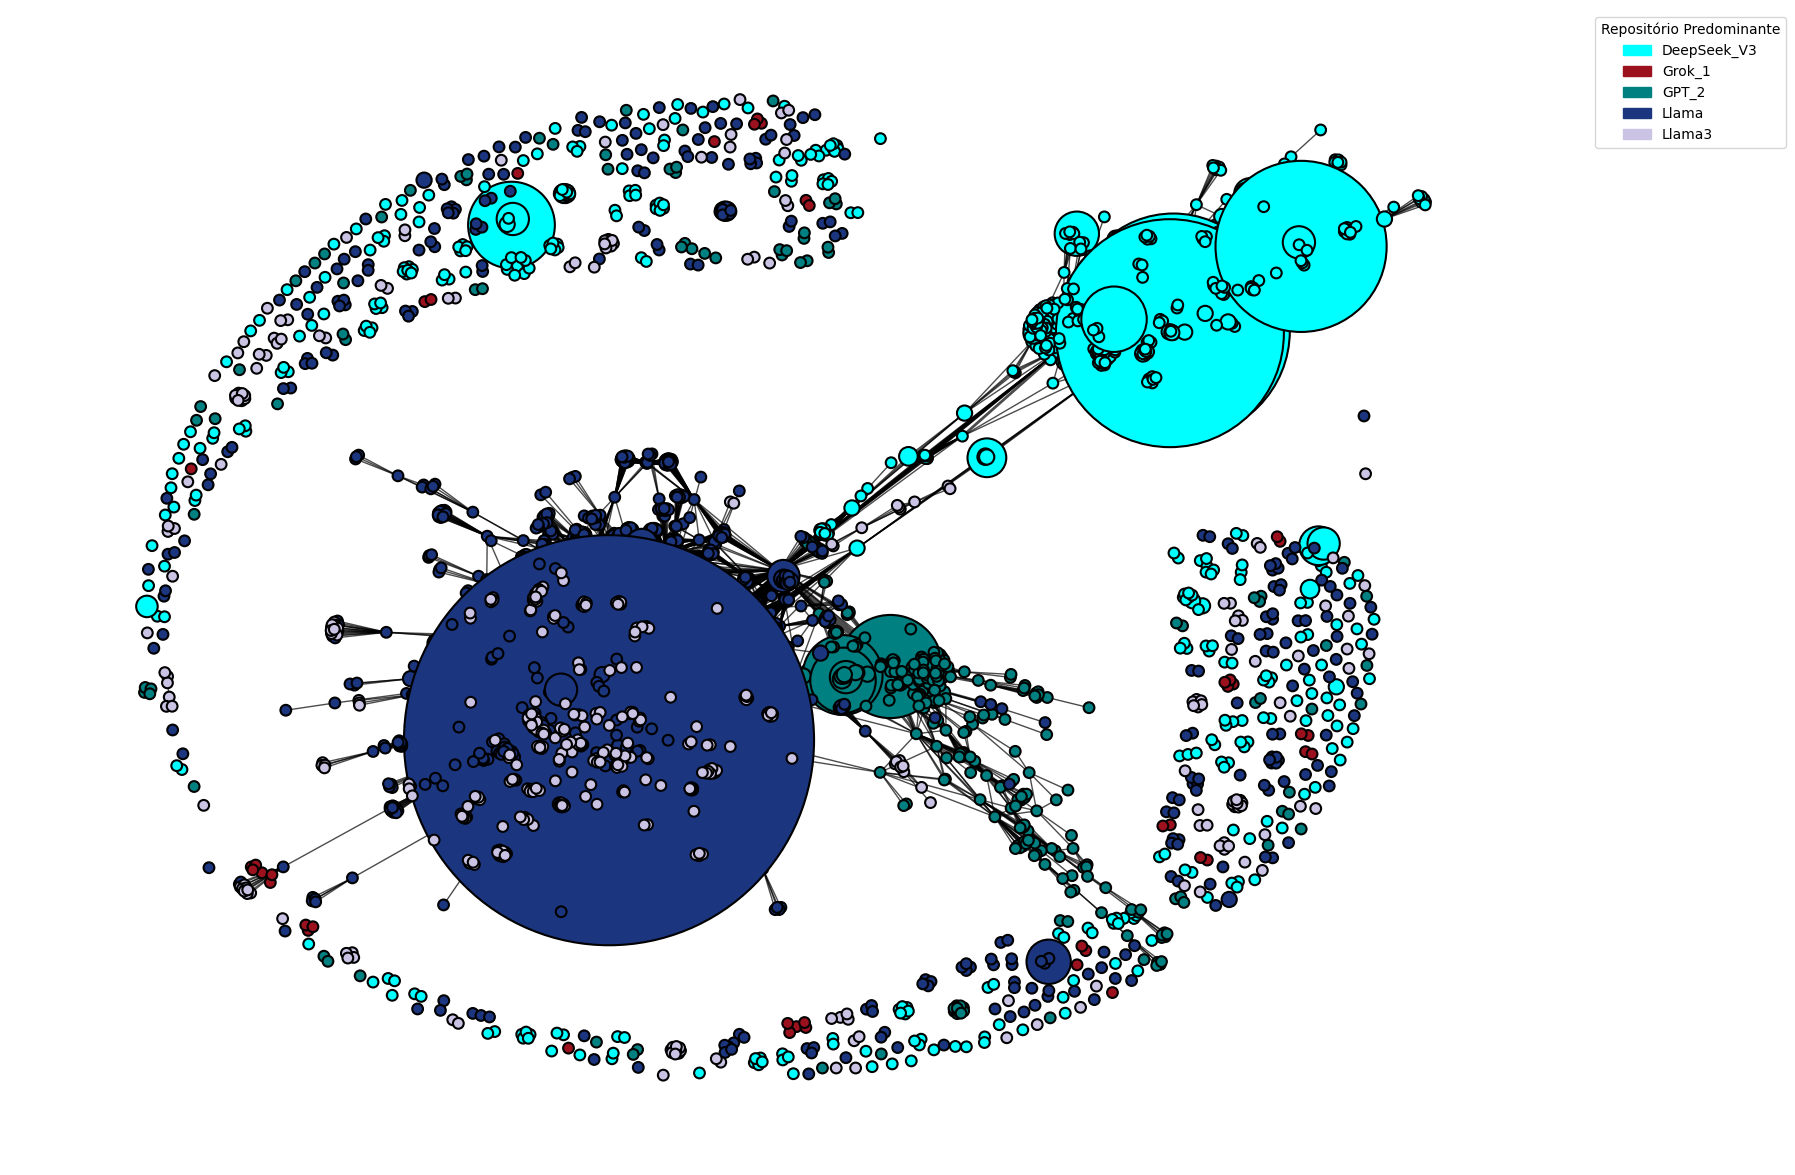

In [ ]:
plotar_grafo(g)

**Somente *issues* validadas como relacionadas à ética**

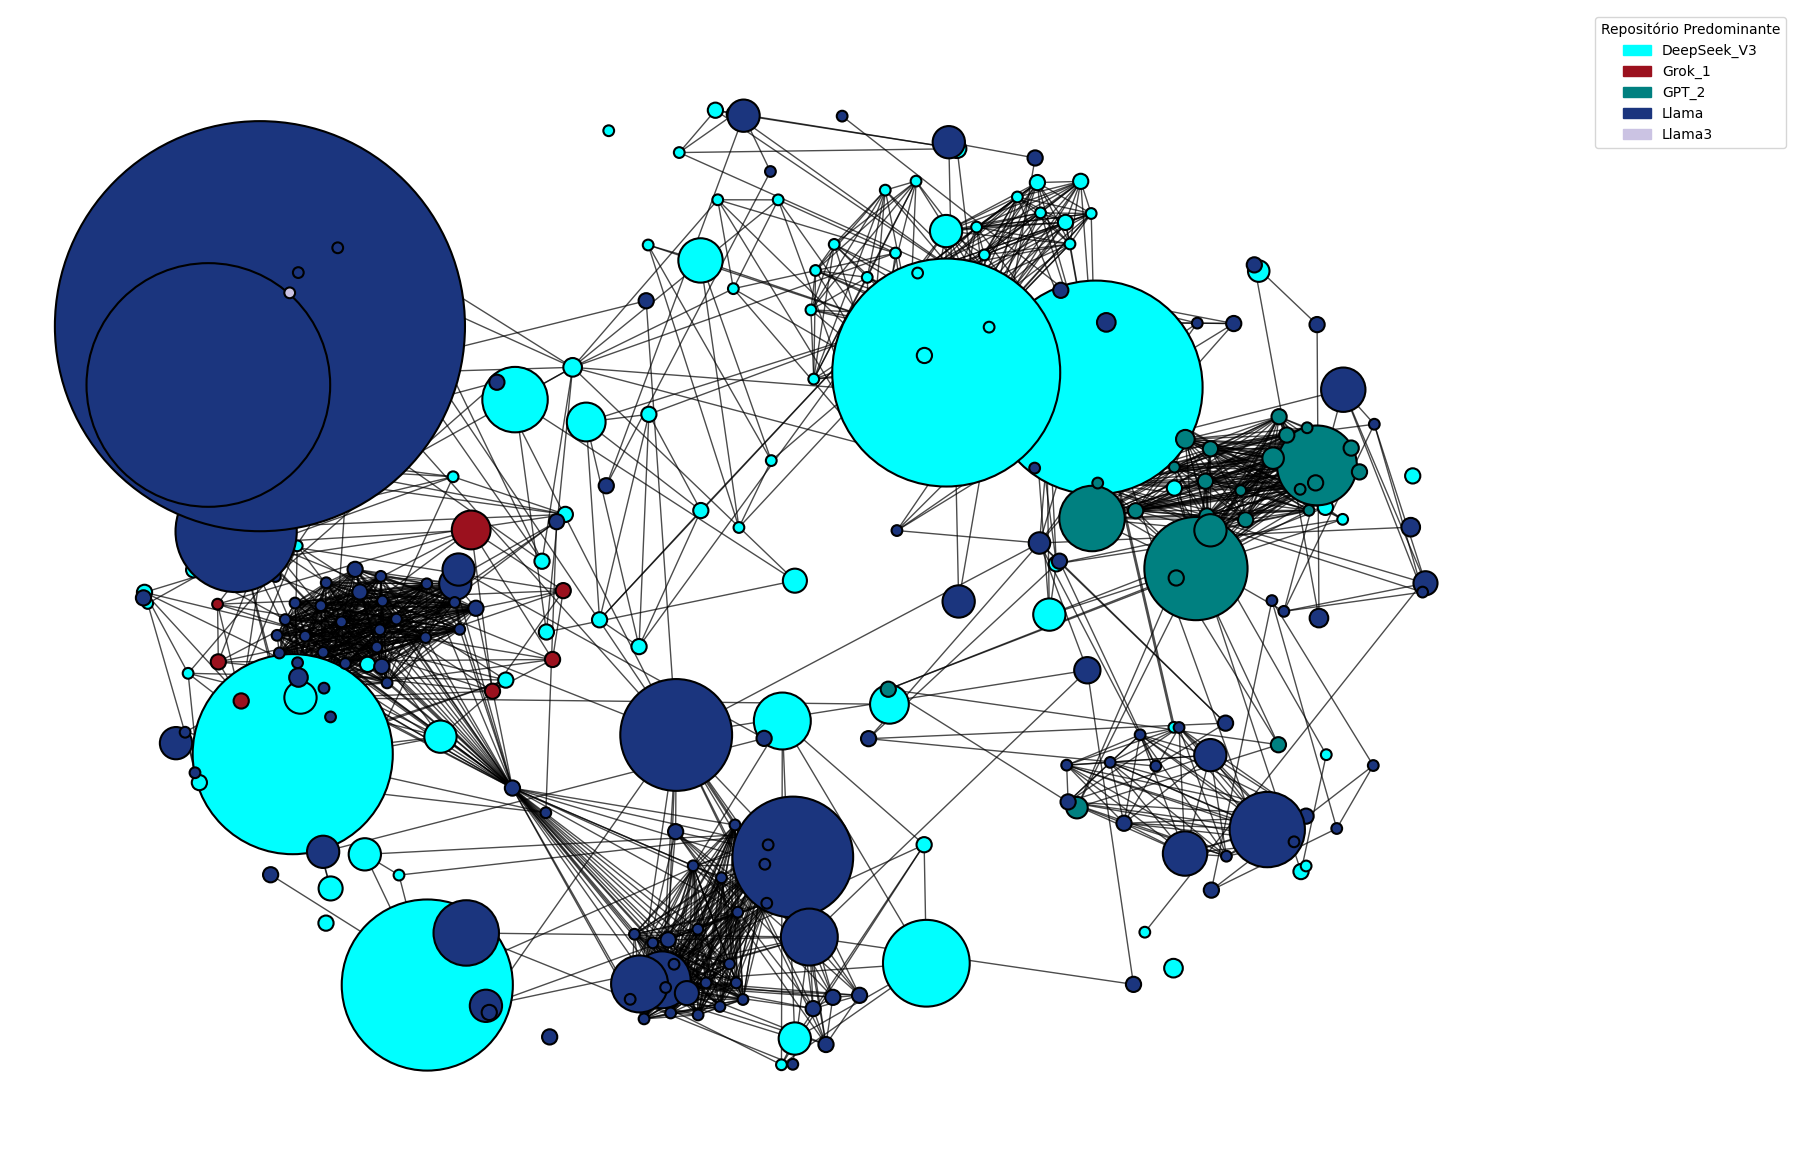

In [ ]:
plotar_grafo(g_validados)

**Somente *issues* INVALIDADAS como relacionadas à ética**

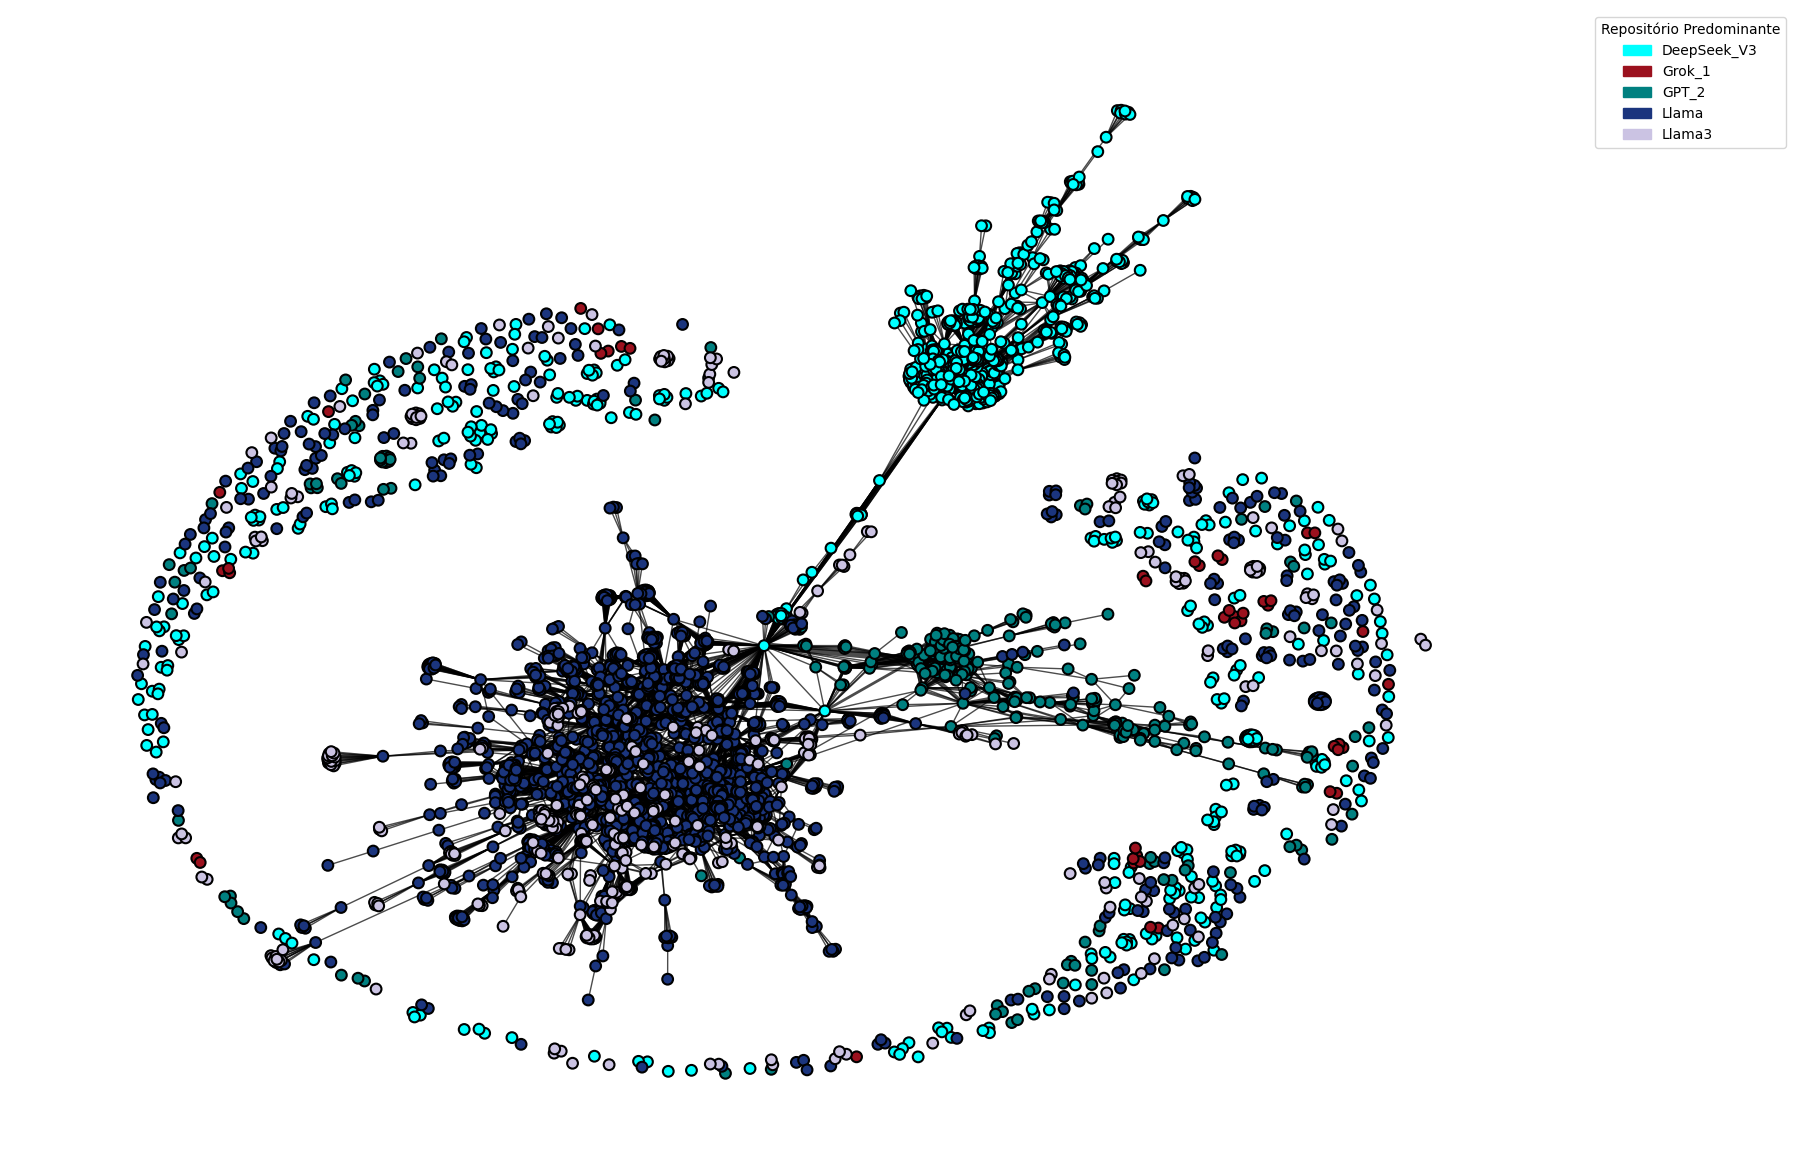

In [ ]:
plotar_grafo(g_invalidados)

# Análise Desempenho

## Reimplementando com contagem de operações básicas

In [59]:
#matriz de adjacência, nós se conectam pela quantidade de issues em ambos. Se 2 usuarios participaram de 3 issues ao mesmo tempo, eles tem 3 conexoes
class Grafo:
  def __init__(self, lista_nos):
    self.lista_nos = lista_nos
    self.matrizAdjacencia = []
    self.inicializaMatrizAdjacencia()
    self.criar_aresta()

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ INICIALIZA MATRIZ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def inicializaMatrizAdjacencia(self):
    n = len(self.lista_nos)
    self.matrizAdjacencia = [[[] for _ in range(n)] for _ in range(n)]
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ EXTRAI NO DADO UM ID ~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def extraiNo_dadoId(self, id):
    for i in self.lista_nos:
      if i.id_participante == id:
        return i
    return None
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ CRIA ARESTA ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def criar_aresta(self):
    dicionario_issues = {}
    for i in self.lista_nos:
      for j in i.issues:
        dicionario_issues[j.id_issue] = j

    h = Max_Heap()
    h.constroi_max_heap(list(dicionario_issues.values()))

    heaps_usuarios = [] #id usuario + respectivo heap

    for no in self.lista_nos:
      h_usuario = Max_Heap()
      h_usuario.constroi_max_heap(no.issues)
      elemento_usuario = {"id_participante": no.id_participante, "heap": h_usuario}
      heaps_usuarios.append(elemento_usuario)


    while h.tam > 0:
      m_val = h.extraiMax()
      m_id = m_val.id_issue
      nome_repo = m_val.repositorio.name

      usuariosM = []

      for i in range(len(heaps_usuarios)):
          while heaps_usuarios[i]['heap'].tam > 0:
              s = heaps_usuarios[i]['heap'].heap_max()

              if s.id_issue == m_id:
                  heaps_usuarios[i]['heap'].extraiMax()
                  usuariosM.append(i)
              else:
                break

      for i in range(len(usuariosM)):
          for j in range(i + 1, len(usuariosM)):
              u1 = usuariosM[i]
              u2 = usuariosM[j]

              aresta = (m_id, nome_repo)

              self.matrizAdjacencia[u1][u2].append(aresta)
              self.matrizAdjacencia[u2][u1].append(aresta)
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~ VIZINHOS DE UM NÓ ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def vizinhos(self, id_participante):
    v = set()

    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == id_participante:
            indice_alvo = i
            break

    if indice_alvo == -1:
        return v

    for j, arestas in enumerate(self.matrizAdjacencia[indice_alvo]):
      if len(arestas) > 0:
        id_vizinho = self.lista_nos[j].id_participante
        v.add(id_vizinho)
    return v
#===============================================================================

#===============================================================================
#~~~~~~~~~~~~~~~~~~~~~~ VERIFICA REPOS QUE USUARIO PARTICIPOU ~~~~~~~~~~~~~~~~~~
  def verificaReposUsuario(self, usuario):
    #verificar se nas intersecoes do usuario se ocorreu alguma interacao em um repo que nao esteja em repo_visitado
    repo_visitado = set()
    indice_alvo = -1
    for i, no in enumerate(self.lista_nos):
        if no.id_participante == usuario.id_participante:
            indice_alvo = i
            break
    for arestas in self.matrizAdjacencia[indice_alvo]:
      for id, nome in arestas:
        repo_visitado.add(nome)

    return repo_visitado
#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ DFS ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def dfs(self, no, visitado, cont_op_basica=0):
    #pegar as intersecoes e verificar se um usuario participou de mais de um repositorio
    visitado[no.id_participante] = True
    repos = self.verificaReposUsuario(no)
    id_usuarios_transversais = set()
    if len(repos) > 1:
      id_usuarios_transversais.add(no.id_participante)
    for w in self.vizinhos(no.id_participante):
      cont_op_basica+=1
      print(f'Quantidade de operações básica corrente: {cont_op_basica}')
      if not visitado.get(w, False):
        vizinho = self.extraiNo_dadoId(w)
        if vizinho:
            cont_op_basica, _ = self.dfs(vizinho, visitado, cont_op_basica)
    if len(id_usuarios_transversais) < 1:
      return cont_op_basica, "Não houve usuários que participaram de mais de um repositório"

    print(f'\nTotal de operações básicas = {cont_op_basica}')
    return cont_op_basica, id_usuarios_transversais

#===============================================================================

#===============================================================================
# ~~~~~~~~~~~~~~~~~~~~~~~~~ ALGORITMO DE BRANDES ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  def brandes(self, cont_op_basica=0):
    centralidade_participantes = {}
    for n in self.lista_nos:
      centralidade_participantes[n.id_participante] = 0

    for s in self.lista_nos:
      s_id = s.id_participante
      pilha_s = [] #uma lista acessada pelo último elemento (topo)

      p_v = {}
      for n in self.lista_nos:
        p_v[n.id_participante] = []

      sigma = {}
      for si in self.lista_nos:
        sigma[si.id_participante] = 0
      sigma[s_id] = 1

      dist = {}
      for n in self.lista_nos:
        dist[n.id_participante] = -1
      dist[s_id] = 0

      fila_q = [s_id] #uma lista acessada primeiro elemento (frente)
      while fila_q:
        v = fila_q.pop(0)
        pilha_s.append(v)

        for w in self.vizinhos(v):
          if dist[w] < 0:
            fila_q.append(w)
            dist[w] = dist[v]+1

          if dist[w] == dist[v]+1:
            sigma[w]+=sigma[v]
            p_v[w].append(v)

      delta = {}
      for n in self.lista_nos:
        delta[n.id_participante] = 0

      while pilha_s:
        w = pilha_s.pop()
        for v in p_v[w]:
          delta[v] += (sigma[v] / sigma[w]) * (1 + delta[w])
          cont_op_basica+=1
          print(f'Quantidade de operações básica corrente: {cont_op_basica}')

        if w != s_id:
          centralidade_participantes[w]+=delta[w]

    for i in centralidade_participantes:
      centralidade_participantes[i] = floor(centralidade_participantes[i]/2)

    return cont_op_basica, centralidade_participantes
#===============================================================================

## Dataset Inteiro

In [60]:
g = Grafo(participantes_tratados)

### Transversalidade via DFS

In [61]:
dicionario_visitados = {}
for no in participantes_tratados:
    dicionario_visitados[no.id_participante] = False

c_dfs_inteira, s = g.dfs(participantes_tratados[0], dicionario_visitados)
print(f'Foram realizada {c_dfs_inteira} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 28542
Quantidade de operações básica corrente: 28543
Quantidade de operações básica corrente: 28544
Quantidade de operações básica corrente: 28545
Quantidade de operações básica corrente: 28546
Quantidade de operações básica corrente: 28547
Quantidade de operações básica corrente: 28548
Quantidade de operações básica corrente: 28549
Quantidade de operações básica corrente: 28550
Quantidade de operações básica corrente: 28551
Quantidade de operações básica corrente: 28552
Quantidade de operações básica corrente: 28553
Quantidade de operações básica corrente: 28554
Quantidade de operações básica corrente: 28555
Quantidade de operações básica corrente: 28556
Quantidade de operações básica corrente: 28557
Quantidade de operações básica corrente: 28558
Quantidade de operações básica corrente: 28559
Quantidade de operações básica corrente: 28560
Quantidade de operações básica corrente: 28561
Q

In [62]:
dicionario_visitados = {}
for n in g.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()
ops_basicas = []

for no in g.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        c_dfs_componente_conexa, resultado_dfs = g.dfs(no, dicionario_visitados)
        ops_basicas.append(c_dfs_componente_conexa)

        if isinstance(resultado_dfs, set):
            todos_transversais.update(resultado_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas}')

print(f"\nTotal de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

c_dfs_conexa_max = max(ops_basicas)
print(f'Foram realizada {c_dfs_conexa_max} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 31957
Quantidade de operações básica corrente: 31958
Quantidade de operações básica corrente: 31959
Quantidade de operações básica corrente: 31960
Quantidade de operações básica corrente: 31961
Quantidade de operações básica corrente: 31962
Quantidade de operações básica corrente: 31963
Quantidade de operações básica corrente: 31964
Quantidade de operações básica corrente: 31965
Quantidade de operações básica corrente: 31966
Quantidade de operações básica corrente: 31967
Quantidade de operações básica corrente: 31968
Quantidade de operações básica corrente: 31969
Quantidade de operações básica corrente: 31970
Quantidade de operações básica corrente: 31971
Quantidade de operações básica corrente: 31972
Quantidade de operações básica corrente: 31973
Quantidade de operações básica corrente: 31974
Quantidade de operações básica corrente: 31975
Quantidade de operações básica corrente: 31976
Q

### Transversalidade via Algoritmo de Brandes

In [63]:
brandes_inteira, cb = g.brandes()
print(f'\nForam realizadas {brandes_inteira} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 13077898
Quantidade de operações básica corrente: 13077899
Quantidade de operações básica corrente: 13077900
Quantidade de operações básica corrente: 13077901
Quantidade de operações básica corrente: 13077902
Quantidade de operações básica corrente: 13077903
Quantidade de operações básica corrente: 13077904
Quantidade de operações básica corrente: 13077905
Quantidade de operações básica corrente: 13077906
Quantidade de operações básica corrente: 13077907
Quantidade de operações básica corrente: 13077908
Quantidade de operações básica corrente: 13077909
Quantidade de operações básica corrente: 13077910
Quantidade de operações básica corrente: 13077911
Quantidade de operações básica corrente: 13077912
Quantidade de operações básica corrente: 13077913
Quantidade de operações básica corrente: 13077914
Quantidade de operações básica corrente: 13077915
Quantidade de operações básica corrente: 

## Dataset Validadas

In [64]:
g_validados = Grafo(participantesValidados_tratados)

### Transversalidade via DFS

In [65]:
dicionario_visitados = {}
for no in participantesValidados_tratados:
    dicionario_visitados[no.id_participante] = False

c_dfs_validada, s = g_validados.dfs(participantesValidados_tratados[0], dicionario_visitados)
print(f'Foram realizada {c_dfs_validada} operações básicas')

Quantidade de operações básica corrente: 1
Quantidade de operações básica corrente: 2
Quantidade de operações básica corrente: 3
Quantidade de operações básica corrente: 4
Quantidade de operações básica corrente: 5
Quantidade de operações básica corrente: 6
Quantidade de operações básica corrente: 7
Quantidade de operações básica corrente: 8
Quantidade de operações básica corrente: 9
Quantidade de operações básica corrente: 10
Quantidade de operações básica corrente: 11
Quantidade de operações básica corrente: 12
Quantidade de operações básica corrente: 13
Quantidade de operações básica corrente: 14
Quantidade de operações básica corrente: 15
Quantidade de operações básica corrente: 16
Quantidade de operações básica corrente: 17
Quantidade de operações básica corrente: 18
Quantidade de operações básica corrente: 19
Quantidade de operações básica corrente: 20
Foram realizada 20 operações básicas


In [66]:
dicionario_visitados = {}
for n in g_validados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()
ops_basicas = []

for no in g_validados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        c_dfs_componente_conexa_validada, resultadoValidados_dfs = g_validados.dfs(no, dicionario_visitados)
        ops_basicas.append(c_dfs_componente_conexa_validada)

        if isinstance(resultadoValidados_dfs, set):
            todos_transversais.update(resultadoValidados_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"Total de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

c_dfs_conexa_validada_max = max(ops_basicas)
print(f'Foram realizada {c_dfs_conexa_validada_max} operações básicas')

Componente Conexas: 1 (Iniciando pelo usuário 2)...
Quantidade de operações básica corrente: 1
Quantidade de operações básica corrente: 2
Quantidade de operações básica corrente: 3
Quantidade de operações básica corrente: 4
Quantidade de operações básica corrente: 5
Quantidade de operações básica corrente: 6
Quantidade de operações básica corrente: 7
Quantidade de operações básica corrente: 8
Quantidade de operações básica corrente: 9
Quantidade de operações básica corrente: 10
Quantidade de operações básica corrente: 11
Quantidade de operações básica corrente: 12
Quantidade de operações básica corrente: 13
Quantidade de operações básica corrente: 14
Quantidade de operações básica corrente: 15
Quantidade de operações básica corrente: 16
Quantidade de operações básica corrente: 17
Quantidade de operações básica corrente: 18
Quantidade de operações básica corrente: 19
Quantidade de operações básica corrente: 20
Componente Conexas: 2 (Iniciando pelo usuário 37)...
Quantidade de operações 

### Transversalidade via Algoritmo de Brandes

In [67]:
brandes_validada, cb_validada = g_validados.brandes()
print(f'\nForam realizadas {brandes_validada} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 4822
Quantidade de operações básica corrente: 4823
Quantidade de operações básica corrente: 4824
Quantidade de operações básica corrente: 4825
Quantidade de operações básica corrente: 4826
Quantidade de operações básica corrente: 4827
Quantidade de operações básica corrente: 4828
Quantidade de operações básica corrente: 4829
Quantidade de operações básica corrente: 4830
Quantidade de operações básica corrente: 4831
Quantidade de operações básica corrente: 4832
Quantidade de operações básica corrente: 4833
Quantidade de operações básica corrente: 4834
Quantidade de operações básica corrente: 4835
Quantidade de operações básica corrente: 4836
Quantidade de operações básica corrente: 4837
Quantidade de operações básica corrente: 4838
Quantidade de operações básica corrente: 4839
Quantidade de operações básica corrente: 4840
Quantidade de operações básica corrente: 4841
Quantidade de operaçõ

## Dataset Invalidadas

In [68]:
g_invalidados = Grafo(participantesInvalidados_tratados)

### Transversalidade via DFS

In [ ]:
dicionario_visitados = {}
for no in participantesInvalidados_tratados:
    dicionario_visitados[no.id_participante] = False

c_dfs_invalidada, s = g_invalidados.dfs(participantesInvalidados_tratados[0], dicionario_visitados)
print(f'Foram realizada {c_dfs_invalidada} operações básicas')

In [ ]:
dicionario_visitados = {}
for n in g_invalidados.lista_nos:
  dicionario_visitados[n.id_participante] = False

total_componentes_conexas = 0
todos_transversais = set()
ops_basicas = []

for no in g_invalidados.lista_nos:
    if not dicionario_visitados[no.id_participante]:
        total_componentes_conexas += 1
        print(f"Componente Conexas: {total_componentes_conexas} (Iniciando pelo usuário {no.id_participante})...")

        c_dfs_componente_conexa_invalidada, resultadoinValidados_dfs = g_invalidados.dfs(no, dicionario_visitados)
        ops_basicas.append(c_dfs_componente_conexa_invalidada)

        if isinstance(resultadoinValidados_dfs, set):
            todos_transversais.update(resultadoinValidados_dfs)

print(f'\n')
if total_componentes_conexas == 1:
    print("A rede é uma grande componente conexa. Existe um caminho entre qualquer par de desenvolvedores")
else:
    print(f'A rede é fragmentada em {total_componentes_conexas} componentes conexas')

print(f"Total de Usuários Transversais: {len(todos_transversais)}")
if len(todos_transversais) > 0:
    print(f"IDs desses usuários: {list(todos_transversais)}")

c_dfs_conexa_invalidada_max = max(ops_basicas)
print(f'Foram realizada {c_dfs_conexa_invalidada_max} operações básicas')

### Transversalidade via Algoritmo de Brandes

In [71]:
brandes_invalidada, cb_invalidada = g_invalidados.brandes()
print(f'\nForam realizadas {brandes_invalidada} operações básicas')

A saída de streaming foi truncada nas últimas 5000 linhas.
Quantidade de operações básica corrente: 11404903
Quantidade de operações básica corrente: 11404904
Quantidade de operações básica corrente: 11404905
Quantidade de operações básica corrente: 11404906
Quantidade de operações básica corrente: 11404907
Quantidade de operações básica corrente: 11404908
Quantidade de operações básica corrente: 11404909
Quantidade de operações básica corrente: 11404910
Quantidade de operações básica corrente: 11404911
Quantidade de operações básica corrente: 11404912
Quantidade de operações básica corrente: 11404913
Quantidade de operações básica corrente: 11404914
Quantidade de operações básica corrente: 11404915
Quantidade de operações básica corrente: 11404916
Quantidade de operações básica corrente: 11404917
Quantidade de operações básica corrente: 11404918
Quantidade de operações básica corrente: 11404919
Quantidade de operações básica corrente: 11404920
Quantidade de operações básica corrente: 

# Visualização Comparação de Performance

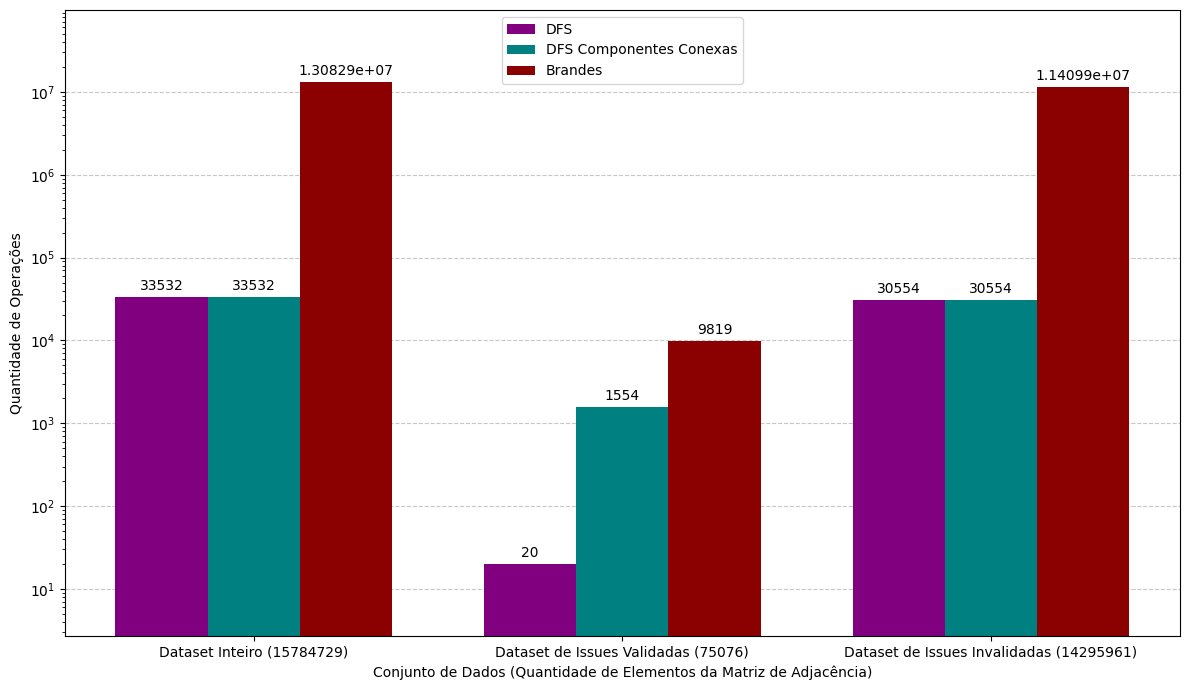

In [76]:
tamanhos = [len(g.lista_nos)**2, len(g_validados.lista_nos)**2, len(g_invalidados.lista_nos)**2]

grupos_x = [
    f'Dataset Inteiro ({tamanhos[0]})',
    f'Dataset de Issues Validadas ({tamanhos[1]})',
    f'Dataset de Issues Invalidadas ({tamanhos[2]})'
]

x_pos = np.arange(len(grupos_x))
largura = 0.25

y_dfs = [c_dfs_inteira, c_dfs_validada, c_dfs_invalidada]
y_dfs_conexa = [c_dfs_conexa_max, c_dfs_conexa_validada_max, c_dfs_conexa_invalidada_max]
y_brandes = [brandes_inteira, brandes_validada, brandes_invalidada]

fig, ax = plt.subplots(figsize=(12, 7))

barras_dfs = ax.bar(x_pos - largura, y_dfs, width=largura, label='DFS', color='purple')
barras_dfs_conexa = ax.bar(x_pos, y_dfs_conexa, width=largura, label='DFS Componentes Conexas', color='teal')
barras_brandes = ax.bar(x_pos + largura, y_brandes, width=largura, label='Brandes', color='darkred')

ax.set_yscale('log')
ax.bar_label(barras_dfs, padding=3)
ax.bar_label(barras_dfs_conexa, padding=3)
ax.bar_label(barras_brandes, padding=3)

ax.set_xticks(x_pos)
ax.set_xticklabels(grupos_x)
ax.set_ylabel('Quantidade de Operações')
ax.set_xlabel('Conjunto de Dados (Quantidade de Elementos da Matriz de Adjacência)')

ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
plt.margins(y=0.15)

plt.tight_layout()
plt.show()